# Data Loading

In [1]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.262976
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,5.008428
948,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.157995
3160,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.532205
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.169370


# Prediction Analysis

## Metrics

In [2]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.420808,0.348346,0.245103,0.495078
Split 1,0.420108,0.418595,0.320292,0.565943
Split 2,0.472521,0.355843,0.233117,0.482822
Split 3,0.443163,0.397021,0.315054,0.561297
Split 4,0.498648,0.341870,0.240365,0.490271
Split 5,0.421939,0.378482,0.305786,0.552979
Split 6,0.484125,0.334846,0.217812,0.466704
Split 7,0.334773,0.370752,0.287411,0.536108
Split 8,0.453891,0.361002,0.283168,0.532135
Split 9,0.473189,0.340198,0.249756,0.499756


# Graph

Text(0, 0.5, 'predicted pIC50')

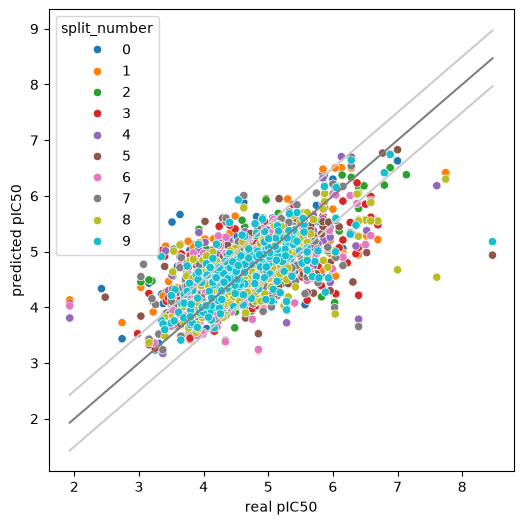

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

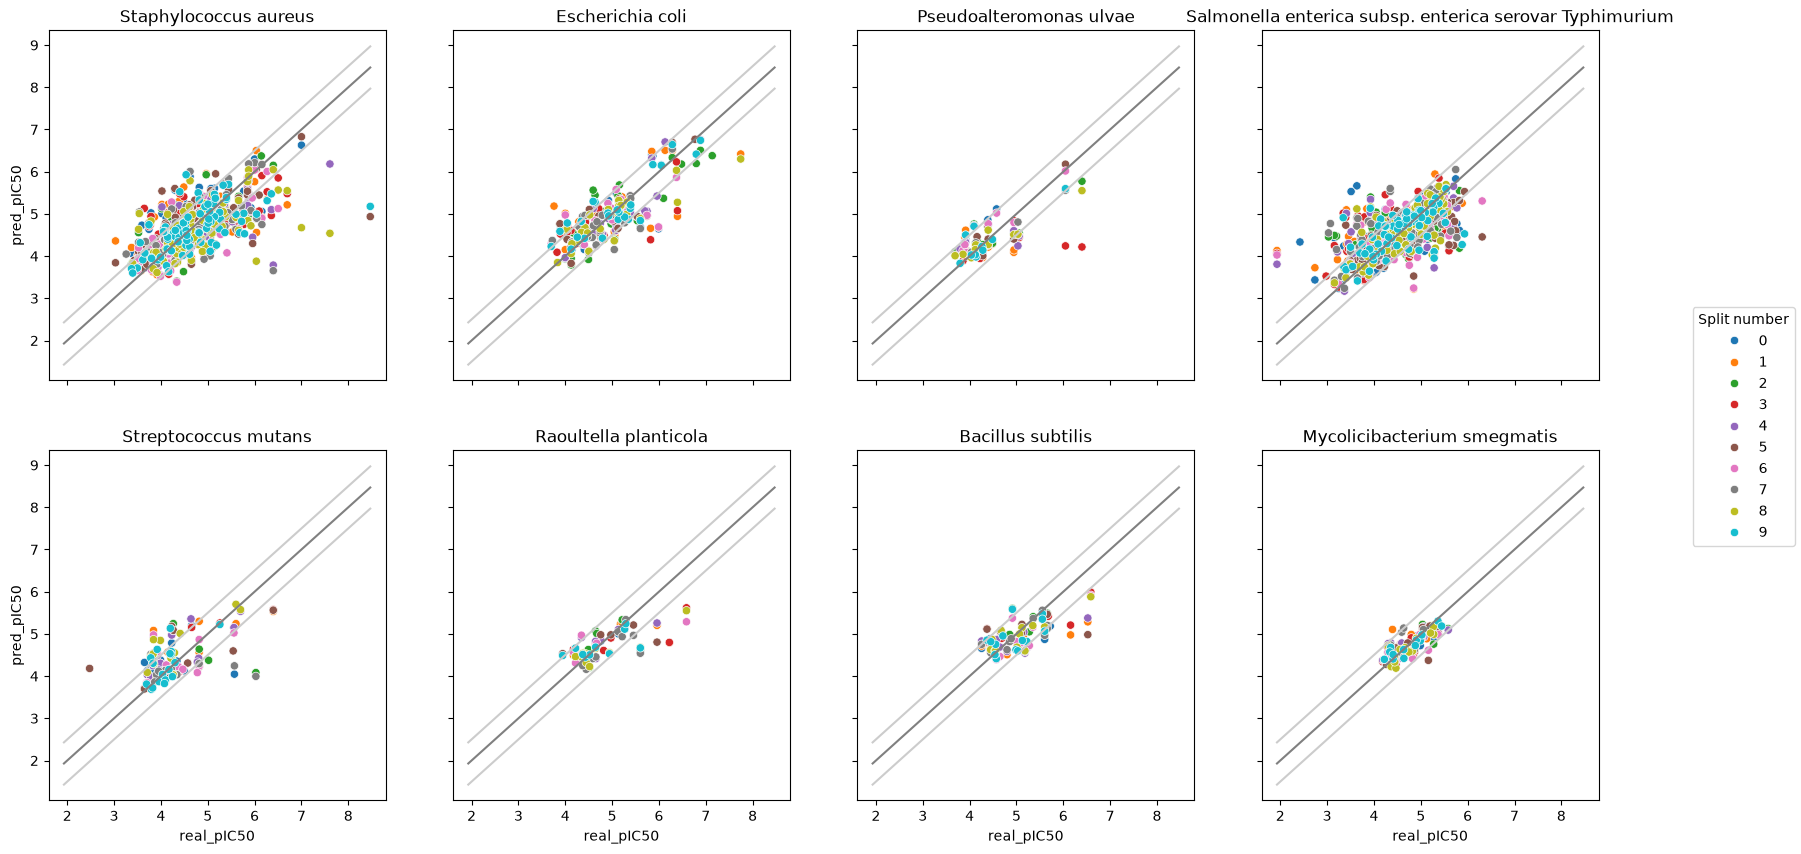

In [4]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [5]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.398,0.096,0.397,0.042,0.554,0.075
Escherichia coli,0.564,0.163,0.338,0.061,0.454,0.086
Pseudoalteromonas ulvae,0.376,0.527,0.327,0.106,0.424,0.189
Salmonella enterica subsp. enterica serovar Typhimurium,0.350,0.070,0.389,0.045,0.553,0.050
Streptococcus mutans,0.139,0.364,0.384,0.102,0.527,0.148
Raoultella planticola,0.398,0.129,0.289,0.056,0.437,0.083
Bacillus subtilis,0.436,0.151,0.303,0.047,0.403,0.082
Mycolicibacterium smegmatis,0.444,0.268,0.187,0.033,0.236,0.034


In [6]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.3941808286930598
MAE 0.3975053613277723
MSE 0.3125897081937553
RMSE 0.5590972260651588
..............
Escherichia coli
r2_score 0.5965972616770183
MAE 0.3391820625844602
MSE 0.21399316929609502
RMSE 0.46259395726284086
..............
Pseudoalteromonas ulvae
r2_score 0.4727372539124518
MAE 0.32672424731469973
MSE 0.21091423995296488
RMSE 0.4592540037418998
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.3589587879195272
MAE 0.38946244866025387
MSE 0.3082079133517796
RMSE 0.5551647623469808
..............
Streptococcus mutans
r2_score 0.2463964009012759
MAE 0.37608354607777456
MSE 0.2841742574814507
RMSE 0.5330799728759754
..............
Raoultella planticola
r2_score 0.4516174868043886
MAE 0.2887538598578185
MSE 0.19707096223337675
RMSE 0.44392675323005343
..............
Bacillus subtilis
r2_score 0.4589497339876967
MAE 0.30249794251025813
MSE 0.16623006816041158
RMSE 0.4077132180349462
..............
Mycolicibacterium s